# Alzheimer MRI — Preprocessing and Data Splits


## 1. Setup
Import libraries, set random seeds, and locate the dataset directory.


In [1]:
import os
from pathlib import Path
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import train_test_split

# Set fixed random seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Locate dataset directory
if Path('data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')
elif Path('../data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('../data/Alzheimer (Preprocessed Data)')
else:
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')

print(f"Dataset path: {DATA_DIR.resolve()}")


Dataset path: C:\Users\usern\Desktop\Alzheimer-Detection\data\Alzheimer (Preprocessed Data)


## 2. Load Image Paths and Labels
Collect image paths and map each class name to an integer index.


In [2]:
# Discover classes and create label mappings
class_folders = sorted([f for f in DATA_DIR.iterdir() if f.is_dir()])
class_names = [f.name for f in class_folders]

class_to_idx = {cls_name: i for i, cls_name in enumerate(class_names)}
idx_to_class = {i: cls_name for cls_name, i in class_to_idx.items()}

print("Class mapping:")
for cls_name, idx in class_to_idx.items():
    print(f"  {idx}: {cls_name}")

# Collect all image paths and labels
image_paths = []
labels = []
IMAGE_EXTS = {'.jpg', '.jpeg', '.png'}

for folder in class_folders:
    for file_path in folder.iterdir():
        if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTS:
            image_paths.append(file_path)
            labels.append(class_to_idx[folder.name])

print(f"\nTotal images loaded: {len(image_paths)}")


Class mapping:
  0: Mild_Demented
  1: Moderate_Demented
  2: Non_Demented
  3: Very_Mild_Demented

Total images loaded: 6400


## 3. Create Stratified Splits
Split the dataset into 70% train, 15% validation, and 15% test using stratified sampling.


In [3]:
# First split: 70% train, 30% temporary (validation + test)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=labels
)

# Second split: divide the 30% equally into 15% validation and 15% test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_labels
)

print(f"Train set:      {len(train_paths):4d} images ({len(train_paths)/len(image_paths)*100:.1f}%)")
print(f"Validation set: {len(val_paths):4d} images ({len(val_paths)/len(image_paths)*100:.1f}%)")
print(f"Test set:       {len(test_paths):4d} images ({len(test_paths)/len(image_paths)*100:.1f}%)")

# Verify zero data leakage between splits
assert len(set(train_paths) & set(val_paths)) == 0, "Error: train and val overlap!"
assert len(set(train_paths) & set(test_paths)) == 0, "Error: train and test overlap!"
assert len(set(val_paths) & set(test_paths)) == 0, "Error: val and test overlap!"
print("\nConfirmed: Zero overlap across train, validation, and test sets.")


Train set:      4480 images (70.0%)
Validation set:  960 images (15.0%)
Test set:        960 images (15.0%)

Confirmed: Zero overlap across train, validation, and test sets.


## 4. Inspect Split Distributions
Verify per-class counts across splits and visualize the distribution.


,Class,Train (70%),Val (15%),Test (15%),Total
0,Mild_Demented,627,134,135,896
1,Moderate_Demented,45,10,9,64
2,Non_Demented,2240,480,480,3200
3,Very_Mild_Demented,1568,336,336,2240


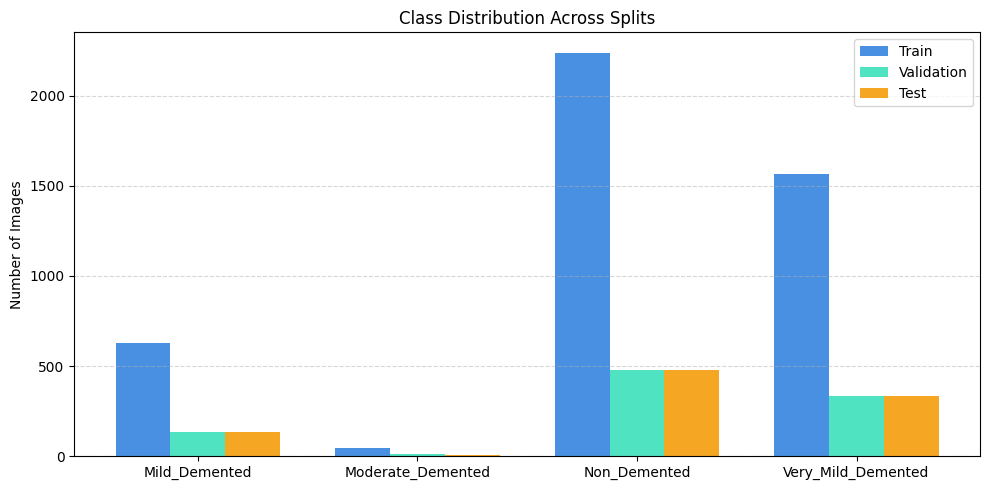

In [4]:
# Build distribution summary table
split_data = []
for idx, cls_name in idx_to_class.items():
    train_count = sum(1 for label in train_labels if label == idx)
    val_count = sum(1 for label in val_labels if label == idx)
    test_count = sum(1 for label in test_labels if label == idx)
    total_count = train_count + val_count + test_count
    
    split_data.append({
        "Class": cls_name,
        "Train (70%)": train_count,
        "Val (15%)": val_count,
        "Test (15%)": test_count,
        "Total": total_count
    })

df_splits = pd.DataFrame(split_data)
display(df_splits)

# Plot grouped bar chart
x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x - width, df_splits["Train (70%)"], width, label="Train", color="#4A90E2")
plt.bar(x, df_splits["Val (15%)"], width, label="Validation", color="#50E3C2")
plt.bar(x + width, df_splits["Test (15%)"], width, label="Test", color="#F5A623")

plt.xticks(x, class_names)
plt.ylabel("Number of Images")
plt.title("Class Distribution Across Splits")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 5. Image Preprocessing and Transforms
Define training data augmentation and deterministic validation/test preprocessing for EfficientNet-B0.


In [5]:
# Standard ImageNet normalization expected by pretrained vision backbones
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training transforms with mild, conservative augmentation
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomRotation(degrees=10),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Validation and test transforms (strictly deterministic, no random augmentation)
eval_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

print("Transforms configured:")
print(" - Train: Resize(224x224), Rotation(10°), HorizontalFlip(p=0.5), ColorJitter, Normalize")
print(" - Eval:  Resize(224x224), Normalize")


Transforms configured:
 - Train: Resize(224x224), Rotation(10°), HorizontalFlip(p=0.5), ColorJitter, Normalize
 - Eval:  Resize(224x224), Normalize


## 6. PyTorch Datasets and DataLoaders
Build a simple PyTorch Dataset and create loaders for train, validation, and test.


In [6]:
class AlzheimerDataset(Dataset):
    """Simple PyTorch Dataset to load 2D MRI slices and convert to 3-channel RGB."""
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        # Open grayscale image and convert to 3-channel RGB for EfficientNet
        image = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = self.labels[idx]
        return image, label

# Create dataset instances
train_dataset = AlzheimerDataset(train_paths, train_labels, transform=train_transform)
val_dataset = AlzheimerDataset(val_paths, val_labels, transform=eval_transform)
test_dataset = AlzheimerDataset(test_paths, test_labels, transform=eval_transform)

# DataLoader parameters (batch_size=32 fits comfortably in 8 GB VRAM)
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("DataLoaders ready:")
print(f" - Train batches: {len(train_loader)} (batch_size={BATCH_SIZE}, shuffle=True)")
print(f" - Val batches:   {len(val_loader)} (batch_size={BATCH_SIZE}, shuffle=False)")
print(f" - Test batches:  {len(test_loader)} (batch_size={BATCH_SIZE}, shuffle=False)")


DataLoaders ready:
 - Train batches: 140 (batch_size=32, shuffle=True)
 - Val batches:   30 (batch_size=32, shuffle=False)
 - Test batches:  30 (batch_size=32, shuffle=False)


## 7. Data Loader Smoke Tests
Fetch one batch from each loader to verify shapes, data types, and label ranges without training.


In [7]:
# Smoke test: inspect one batch from each DataLoader
for name, loader in [("Train", train_loader), ("Validation", val_loader), ("Test", test_loader)]:
    batch_images, batch_labels = next(iter(loader))
    
    print(f"{name} Loader Batch:")
    print(f"  - Images shape: {tuple(batch_images.shape)} | dtype: {batch_images.dtype}")
    print(f"  - Labels shape: {tuple(batch_labels.shape)} | dtype: {batch_labels.dtype}")
    print(f"  - Unique labels in batch: {sorted(batch_labels.unique().tolist())}")
    
    # Assertions
    assert batch_images.shape == (BATCH_SIZE, 3, 224, 224), f"Unexpected image shape: {batch_images.shape}"
    assert batch_labels.shape == (BATCH_SIZE,), f"Unexpected label shape: {batch_labels.shape}"
    assert batch_images.dtype == torch.float32, f"Expected float32 images, got {batch_images.dtype}"
    assert batch_labels.dtype == torch.int64, f"Expected int64 labels, got {batch_labels.dtype}"

print("\nAll DataLoader smoke tests passed successfully!")


Train Loader Batch:
  - Images shape: (32, 3, 224, 224) | dtype: torch.float32
  - Labels shape: (32,) | dtype: torch.int64
  - Unique labels in batch: [0, 1, 2, 3]
Validation Loader Batch:
  - Images shape: (32, 3, 224, 224) | dtype: torch.float32
  - Labels shape: (32,) | dtype: torch.int64
  - Unique labels in batch: [0, 2, 3]
Test Loader Batch:
  - Images shape: (32, 3, 224, 224) | dtype: torch.float32
  - Labels shape: (32,) | dtype: torch.int64
  - Unique labels in batch: [0, 2, 3]

All DataLoader smoke tests passed successfully!


## 8. Summary and Limitations
- **Split Sizes:** Train 4,480 (70%), Validation 960 (15%), Test 960 (15%).
- **Class Stratification:** All four classes are represented in each split, including the minority `Moderate_Demented` class (45 train / 10 val / 9 test).
- **Leakage Prevention:** Verified 0 path overlap among train, validation, and test sets.
- **Preprocessing:** All images are converted to 3-channel RGB, resized to 224 × 224, and normalized with ImageNet statistics. Augmentation is applied only to training data.
- **Limitation — No Patient IDs:** Because filenames lack patient identifiers, splits are slice-level and cannot guarantee patient-level separation.
